In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

In [2]:
df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(6362620, 11)


In [3]:
df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

df = df.drop(
    columns=[
        "nameOrig",
        "nameDest",
        "isFlaggedFraud",
        "newbalanceOrig",
        "newbalanceDest"
    ]
)

X = df.drop(columns=["isFraud"])
y = df["isFraud"]

X = pd.get_dummies(
    X,
    columns=["type"],
    dtype=int
)

In [4]:
train_end = df["step"].quantile(0.70)
validation_end = df["step"].quantile(0.85)

train_mask = df["step"] <= train_end

validation_mask = (
    (df["step"] > train_end) &
    (df["step"] <= validation_end)
)

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

In [5]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf_clean = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

print("Training leakage-resistant Random Forest...")

rf_clean.fit(
    X_train_sample,
    y_train_sample
)

print("Training completed!")

Training leakage-resistant Random Forest...
Training completed!


In [7]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

predictions = rf_clean.predict(X_val)

probabilities = rf_clean.predict_proba(X_val)[:, 1]

print("FRAUDSHIELD AI - PRE-TRANSACTION MODEL")

print("--------------------------------")

print("Precision:", precision_score(y_val, predictions))

print("Recall:", recall_score(y_val, predictions))

print("F1 Score:", f1_score(y_val, predictions))

print("ROC-AUC:", roc_auc_score(y_val, probabilities))

print("PR-AUC:", average_precision_score(y_val, probabilities))

FRAUDSHIELD AI - PRE-TRANSACTION MODEL
--------------------------------
Precision: 0.06915750915750916
Recall: 0.8368794326241135
F1 Score: 0.12775747733116796
ROC-AUC: 0.9953924272627885
PR-AUC: 0.5536584653115204


In [8]:
feature_importance = pd.DataFrame({
    "Feature": X_train_sample.columns,
    "Importance": rf_clean.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

          Feature  Importance
2   oldbalanceOrg    0.294818
1          amount    0.239462
4    type_CASH_IN    0.094584
3  oldbalanceDest    0.091261
7    type_PAYMENT    0.090657
8   type_TRANSFER    0.086106
5   type_CASH_OUT    0.066374
0            step    0.035952
6      type_DEBIT    0.000786


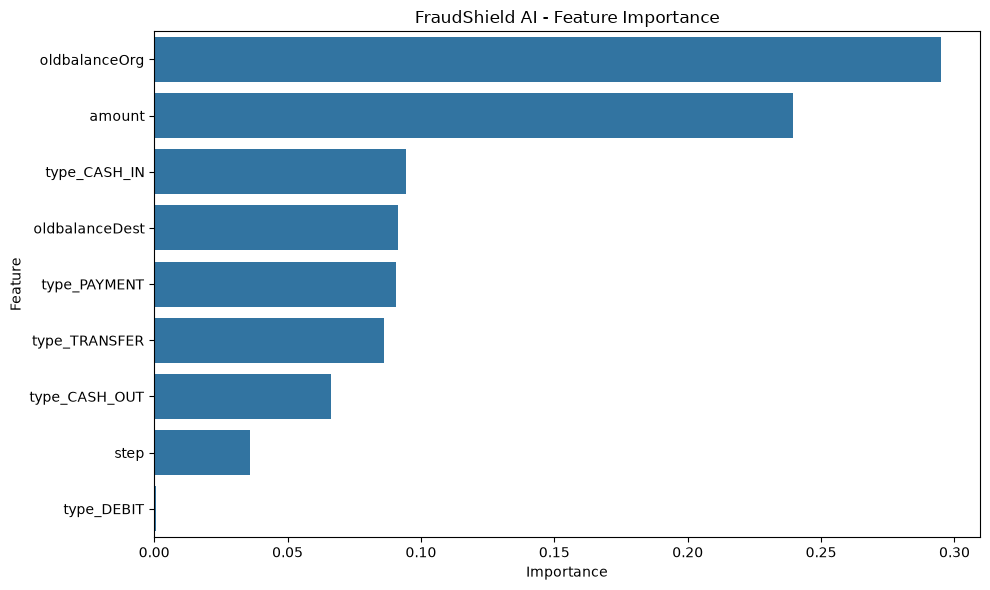

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("FraudShield AI - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_probabilities = rf_clean.predict_proba(X_val)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:

    predictions = (rf_probabilities >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_results = pd.DataFrame(results)

print(threshold_results)

   Threshold  Precision    Recall  F1 Score
0        0.1   0.011167  0.987589  0.022085
1        0.2   0.017054  0.945035  0.033504
2        0.3   0.026098  0.916667  0.050751
3        0.4   0.041622  0.888298  0.079517
4        0.5   0.069158  0.836879  0.127757
5        0.6   0.156749  0.765957  0.260241
6        0.7   0.456051  0.634752  0.530764
7        0.8   0.646925  0.503546  0.566301
8        0.9   0.817352  0.317376  0.457216


In [11]:
from sklearn.metrics import confusion_matrix, classification_report

# Select our provisional threshold
chosen_threshold = 0.8

# Generate predictions
final_predictions = (
    rf_probabilities >= chosen_threshold
).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_val, final_predictions)

print("CONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    final_predictions,
    target_names=["Legitimate", "Fraud"]
))

CONFUSION MATRIX
[[979697    155]
 [   280    284]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    979852
       Fraud       0.65      0.50      0.57       564

    accuracy                           1.00    980416
   macro avg       0.82      0.75      0.78    980416
weighted avg       1.00      1.00      1.00    980416



In [12]:
total_transactions = len(y_val)

flagged_transactions = final_predictions.sum()

actual_fraud = y_val.sum()

print("Total transactions:", total_transactions)
print("Flagged transactions:", flagged_transactions)
print("Actual fraudulent transactions:", actual_fraud)
print("Percentage flagged:", 
      round((flagged_transactions / total_transactions) * 100, 2), "%")

Total transactions: 980416
Flagged transactions: 439
Actual fraudulent transactions: 564
Percentage flagged: 0.04 %


In [13]:
# Recreate chronological split boundaries

train_end = df["step"].quantile(0.70)
validation_end = df["step"].quantile(0.85)

# Identify test transactions

test_mask = df["step"] > validation_end

# Create test features and labels

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Test dataset shape:", X_test.shape)

print("\nTest fraud distribution:")
print(y_test.value_counts())

Test dataset shape: (918617, 9)

Test fraud distribution:
isFraud
0    914611
1      4006
Name: count, dtype: int64


In [14]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate fraud probabilities
test_probabilities = rf_clean.predict_proba(X_test)[:, 1]

# Use our provisional threshold
test_predictions = (
    test_probabilities >= 0.8
).astype(int)

# Calculate metrics
print("FRAUDSHIELD AI - FINAL TEST RESULTS")
print("-----------------------------------")

print("Precision:", precision_score(
    y_test, test_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, test_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, test_predictions, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_test, test_probabilities
))

print("PR-AUC:", average_precision_score(
    y_test, test_probabilities
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, test_predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

FRAUDSHIELD AI - FINAL TEST RESULTS
-----------------------------------
Precision: 0.9099506578947368
Recall: 0.5524213679480778
F1 Score: 0.6874805840323082
ROC-AUC: 0.9947973442908636
PR-AUC: 0.7621880808550286

CONFUSION MATRIX
[[914392    219]
 [  1793   2213]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    914611
       Fraud       0.91      0.55      0.69      4006

    accuracy                           1.00    918617
   macro avg       0.95      0.78      0.84    918617
weighted avg       1.00      1.00      1.00    918617



In [15]:
print("VALIDATION FRAUD RATE:")
print(y_val.mean() * 100, "%")

print("\nTEST FRAUD RATE:")
print(y_test.mean() * 100, "%")


VALIDATION FRAUD RATE:
0.057526600953064826 %

TEST FRAUD RATE:
0.43609034015264253 %


In [16]:
print("Validation fraud cases:", y_val.sum())
print("Test fraud cases:", y_test.sum())

Validation fraud cases: 564
Test fraud cases: 4006


In [17]:
# Compare fraud rates across transaction periods

validation_data = pd.DataFrame({
    "step": df.loc[X_val.index, "step"],
    "isFraud": y_val
})

test_data = pd.DataFrame({
    "step": df.loc[X_test.index, "step"],
    "isFraud": y_test
})

print("VALIDATION PERIOD")
print("First step:", validation_data["step"].min())
print("Last step:", validation_data["step"].max())

print("\nTEST PERIOD")
print("First step:", test_data["step"].min())
print("Last step:", test_data["step"].max())

VALIDATION PERIOD
First step: 324
Last step: 378

TEST PERIOD
First step: 379
Last step: 743


In [18]:
print("VALIDATION FRAUD BY TRANSACTION TYPE")

print(
    df.loc[X_val.index]
    .assign(isFraud=y_val)
    .groupby("type")["isFraud"]
    .agg(["count", "sum", "mean"])
)

VALIDATION FRAUD BY TRANSACTION TYPE
           count  sum      mean
type                           
CASH_IN   217839    0  0.000000
CASH_OUT  344551  282  0.000818
DEBIT       7080    0  0.000000
PAYMENT   327506    0  0.000000
TRANSFER   83440  282  0.003380


In [19]:
print("TEST FRAUD BY TRANSACTION TYPE")

print(
    df.loc[X_test.index]
    .assign(isFraud=y_test)
    .groupby("type")["isFraud"]
    .agg(["count", "sum", "mean"])
)

TEST FRAUD BY TRANSACTION TYPE
           count   sum      mean
type                            
CASH_IN   204069     0  0.000000
CASH_OUT  310302  2003  0.006455
DEBIT       6588     0  0.000000
PAYMENT   317437     0  0.000000
TRANSFER   80221  2003  0.024969
